# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [4]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` podría convertirse a tipo entero (`int64`) ya que representa años cumplidos.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [5]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [6]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [7]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad`: Presenta un rango coherente entre **18 y 75 años**, con un promedio de **38.2 años** y una mediana de **38.0 años**, lo que indica una distribución simétrica sin sesgos pronunciados.
* `nivel_ingreso`: Va desde **$8,000** hasta **$74,790.84**, con una media de **$30,019.70** muy cercana a la mediana de **$30,023.75**, reflejando un nivel socioeconómico con distribución normal.
* `visitas_mes`: Los usuarios visitan la plataforma entre **1 y 25 veces al mes**, con un promedio de **10.03 visitas**, mostrando una actividad recurrente y dentro de rangos normales.
* `compras_mes`: Varía de **0 a 8 compras mensuales**, con un promedio de **1.2 compras**; más del 25% de los usuarios no realizaron compras en el último mes (percentil 25% = 0).
* `gasto_publicidad_dirigida`: Oscila entre **$0 y $75.51**, con una media de **$20.15** y una mediana de **$19.73**, lo que muestra una inversión en pauta distribuida equitativamente.
* `satisfaccion`: Se mantiene dentro de la escala válida de **1.0 a 5.0**, con un promedio de **3.60** y una desviación estándar baja (**0.68**), indicando una percepción general favorable y consistente.

#### Explorar variables binarias

In [8]:
# Verificar que cada columna tenga únicamente dos valores posibles
print(df[['miembro_premium', 'abandono']].value_counts(normalize=True))

miembro_premium  abandono
0                0           0.716067
                 1           0.144667
1                0           0.133200
                 1           0.006067
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium` — Aproximadamente el **13.9%** de los clientes cuenta con una suscripción premium (sumando los casos con y sin abandono), lo que indica una base predominantemente de usuarios estándar o no suscriptores.
- `abandono` — El **15.1%** de la base de clientes ha abandonado la plataforma (churn)[cite: 18]. Es notable que el abandono es drásticamente menor en usuarios premium (solo un **0.6%** global) en comparación con los no premium (**14.5%**).

#### Explorar variables categóricas

In [9]:
# Verificar el número de valores únicos por variable categórica
df[['tipo_dispositivo', 'region']].nunique()

tipo_dispositivo    3
region              4
dtype: int64

In [10]:
# Explorar variables categóricas y cómo se distribuyen
for col in ['tipo_dispositivo', 'region']:
    print(f"--- Distribución de {col} ---")
    print(df[col].value_counts(normalize=True))
    print()

--- Distribución de tipo_dispositivo ---
móvil         0.654533
escritorio    0.248000
tablet        0.097467
Name: tipo_dispositivo, dtype: float64

--- Distribución de region ---
norte    0.2930
oeste    0.2540
sur      0.2484
este     0.2046
Name: region, dtype: float64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — Contiene **3 categorías únicas**. Predomina el uso de **móvil** con un **65.5%**, seguido de **escritorio** (**24.8%**) y **tablet** (**9.7%**).
- `region` — Contiene **4 categorías únicas**[cite: 19]. La distribución geográfica es bastante equitativa: la región **norte** lidera con **29.3%**, seguida por **oeste** (**25.4%**), **sur** (**24.8%**) y **este** (**20.5%**).

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

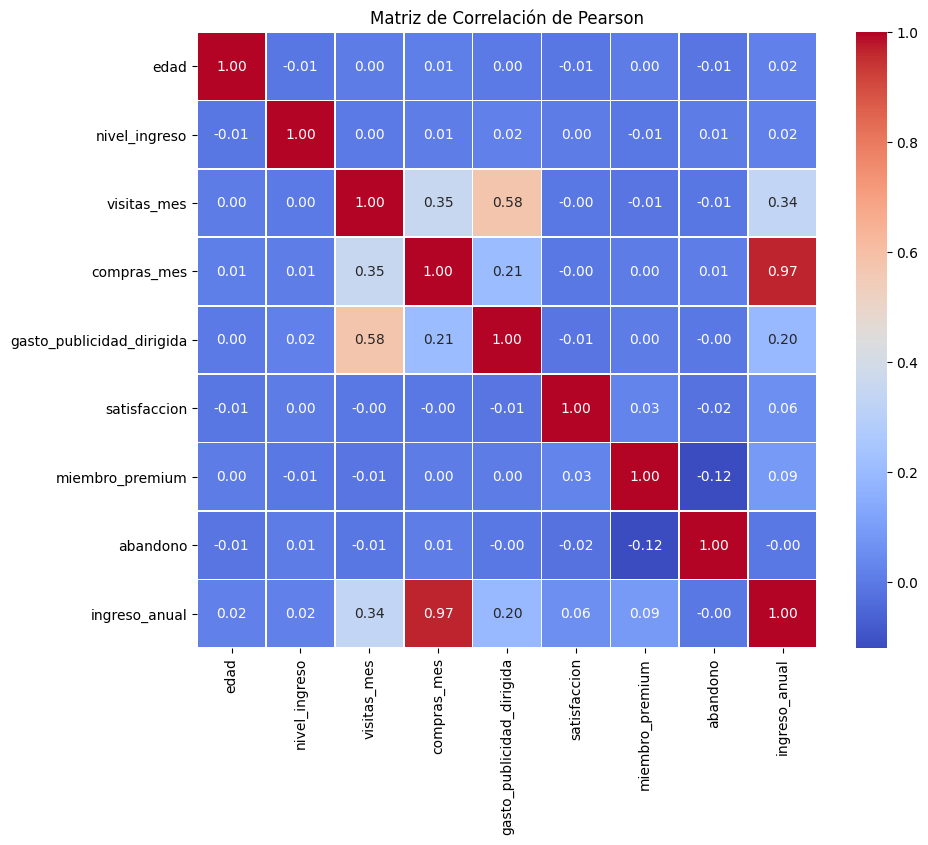

In [11]:
# Visualizar la matriz de correlación para identificar relaciones
# Seleccionar variables numéricas
num_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Calcular matriz de correlación de Pearson
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación de Pearson')
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- Se observa una **correlación positiva muy fuerte** entre `compras_mes` e `ingreso_anual` ($r = 0.97$), lo que indica una colinealidad directa.
- Se aprecia una **correlación positiva moderada** entre `visitas_mes` y `gasto_publicidad_dirigida` ($r = 0.58$), sugiriendo que la publicidad incentiva el tráfico mensual.
- Existe una **correlación positiva moderada** entre `visitas_mes` y `compras_mes` ($r = 0.35$), así como entre `visitas_mes` e `ingreso_anual` ($r = 0.34$).
- La mayoría de las demás variables (`edad`, `nivel_ingreso`, `satisfaccion`) no muestran correlaciones lineales significativas con el resto ($r \approx 0.00$).

Observaciones respecto a `ingreso_anual`  
- Presenta una **correlación casi perfecta** con `compras_mes` ($0.97$), una **relación moderada** con `visitas_mes` ($0.34$) y una **relación débil-moderada** con `gasto_publicidad_dirigida` ($0.20$).


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.
    
- **Decisión sobre el Scatterplot general:**  
No se incluye un scatterplot general (pairplot) debido a que el conjunto de datos cuenta con múltiples variables numéricas y 15,000 observaciones. Un gráfico global resultaría saturado, con poca legibilidad y computacionalmente ineficiente. En su lugar, se seleccionan únicamente las relaciones entre pares de variables con correlaciones destacadas en el punto 3.3.

### Scatterplot para pares clave

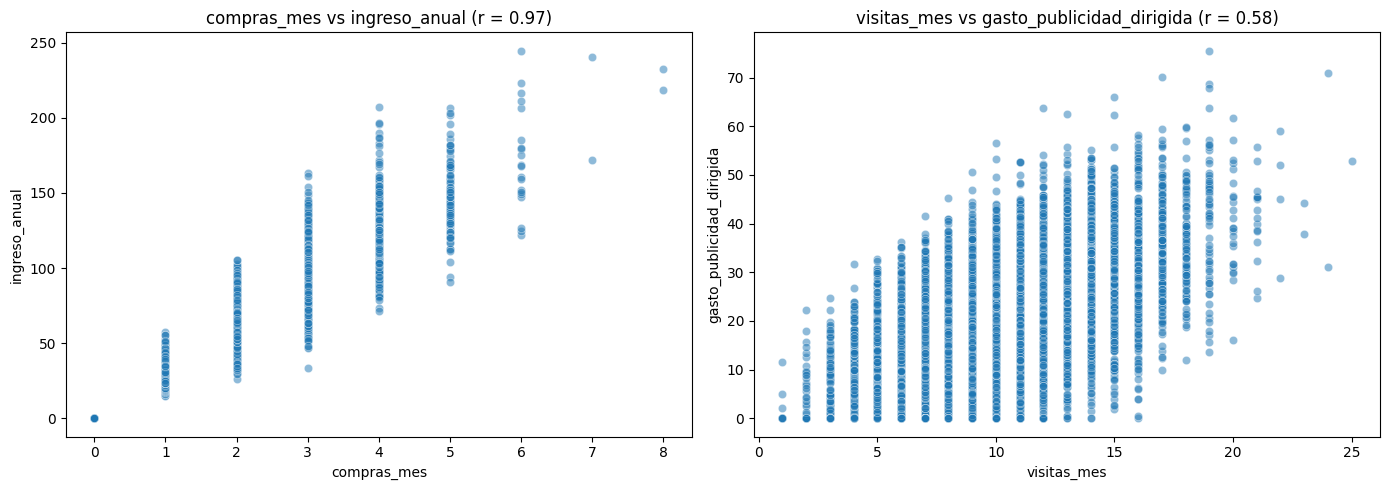

In [13]:
# Visualizar pares de variables con relaciones moderadas o fuertes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Par 1: compras_mes vs ingreso_anual
sns.scatterplot(data=df, x='compras_mes', y='ingreso_anual', alpha=0.5, ax=axes[0])
axes[0].set_title('compras_mes vs ingreso_anual (r = 0.97)')

# Par 2: visitas_mes vs gasto_publicidad_dirigida
sns.scatterplot(data=df, x='visitas_mes', y='gasto_publicidad_dirigida', alpha=0.5, ax=axes[1])
axes[1].set_title('visitas_mes vs gasto_publicidad_dirigida (r = 0.58)')

plt.tight_layout()
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

**compras_mes vs ingreso_anual**

- **Dirección**: Positiva muy fuerte ($r = 0.97$).
- **Dispersión**: Media-baja; se forman franjas verticales continuas debido a la naturaleza discreta de `compras_mes` (valores enteros de 0 a 8).
- **Outliers y colinealidad**: Existe una altísima colinealidad entre ambas variables. Se observan algunos puntos dispersos hacia los valores altos de `ingreso_anual` en compras superiores a 4, pero mantienen la clara tendencia ascendente.

**visitas_mes vs gasto_publicidad_dirigida**

- **Dirección**: Positiva moderada ($r = 0.58$).
- **Dispersión**: Media-alta; muestra una estructura en forma de abanico donde la variación del gasto publicitario aumenta a medida que crecen las visitas.
- **Outliers y colinealidad**: No presenta problemas de colinealidad ni outliers atípicos aislados, confirmando una relación constante entre mayor tráfico mensual y mayor inversión en publicidad dirigida.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [14]:
# Calcular correlación entre variables relevantes
df[['compras_mes', 'ingreso_anual', 'visitas_mes', 'gasto_publicidad_dirigida']].corr(method='pearson')

,compras_mes,ingreso_anual,visitas_mes,gasto_publicidad_dirigida
compras_mes,1.000000,0.967149,0.353844,0.207528
ingreso_anual,0.967149,1.000000,0.337147,0.197483
visitas_mes,0.353844,0.337147,1.000000,0.578947
gasto_publicidad_dirigida,0.207528,0.197483,0.578947,1.000000


In [15]:
# Calcular correlación entre variables relevantes
df[['compras_mes', 'ingreso_anual', 'visitas_mes', 'gasto_publicidad_dirigida']].corr(method='spearman')

,compras_mes,ingreso_anual,visitas_mes,gasto_publicidad_dirigida
compras_mes,1.000000,0.967482,0.332943,0.192511
ingreso_anual,0.967482,1.000000,0.320954,0.184999
visitas_mes,0.332943,0.320954,1.000000,0.559267
gasto_publicidad_dirigida,0.192511,0.184999,0.559267,1.000000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

**compras_mes vs ingreso_anual**

- **Correlación Pearson**: $0.9671$ | **Spearman**: $0.9675$.
- **Dirección y Magnitud**: Positiva extremadamente fuerte / casi perfecta.
- **Colinealidad**: Existe una severa colinealidad lineal y no lineal entre ambas variables. Esto confirma que aportan prácticamente la misma información explicativa y se debe considerar omitir una de las dos en modelos predictivos para evitar redundancia.

**visitas_mes vs gasto_publicidad_dirigida**

- **Correlación Pearson**: $0.5789$ | **Spearman**: $0.5593$.
- **Dirección y Magnitud**: Positiva moderada. La cercanía entre ambos coeficientes sugiere una relación montónicamente estable sin sesgos severos por no linealidad extrema.
- **Colinealidad**: Presentan una asociación clara pero sin riesgo de multicolinealidad dañina, por lo que ambas pueden convivir en el análisis.

### Punto-biserial

In [16]:
# Calcular correlación entre variables relevantes
binarias = ['abandono', 'miembro_premium']
numericas = ['visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'ingreso_anual', 'satisfaccion']

df[numericas + binarias].corr().loc[numericas, binarias]

,abandono,miembro_premium
visitas_mes,-0.008943,-0.012657
compras_mes,0.008291,0.003431
gasto_publicidad_dirigida,-0.004586,0.002721
ingreso_anual,-0.002824,0.093099
satisfaccion,-0.023833,0.025734


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**ingreso_anual vs miembro_premium**

- **Relación**: Positiva muy débil ($r = 0.0931$).
- **Magnitud**: Baja / Débil.
- **Diagnóstico**: Los usuarios con mayor `ingreso_anual` presentan una ligera inclinación a ser `miembro_premium`, aunque el efecto es mínimo.

**satisfaccion vs abandono**

- **Relación**: Negativa casi nula ($r = -0.0238$).
- **Magnitud**: Nula / Despreciable.
- **Diagnóstico**: No se observa una correlación lineal directa relevante entre los niveles de satisfacción y la variable de abandono.

### V de Cramér

In [17]:
# Función para calcular V de Cramér
def cramers_v_pandas(var1, var2):
    tabla = pd.crosstab(var1, var2)
    chi2 = ((tabla - (tabla.sum(axis=1).values[:, None] * tabla.sum(axis=0).values / tabla.values.sum())) ** 2 / (tabla.sum(axis=1).values[:, None] * tabla.sum(axis=0).values / tabla.values.sum())).values.sum()
    return (chi2 / (len(var1) * (min(tabla.shape) - 1))) ** 0.5

In [18]:
# Aplicar V de Cramér en variables relevantes

cat_cols = ['tipo_dispositivo', 'region', 'miembro_premium', 'abandono']

pd.DataFrame({
    c1: [cramers_v_pandas(df[c1], df[c2]) for c2 in cat_cols] 
    for c1 in cat_cols
}, index=cat_cols)

,tipo_dispositivo,region,miembro_premium,abandono
tipo_dispositivo,1.000000,0.012378,0.019725,0.007245
region,0.012378,1.000000,0.012574,0.015430
miembro_premium,0.019725,0.012574,1.000000,0.120488
abandono,0.007245,0.015430,0.120488,1.000000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

Observaciones V de Cramér

**miembro_premium vs abandono**

- **Asociación**: $V = 0.1205$.
- **Magnitud**: Débil / Baja ($V < 0.20$).
- **Interpretación**: Es el cruce categórico con mayor asociación de la matriz, mostrando una leve relación entre el tipo de suscripción (`miembro_premium`) y el `abandono`, aunque sigue siendo un vínculo modesto.

**tipo_dispositivo / region vs resto de variables categóricas**

- **Asociación**: Valores entre $0.0072$ y $0.0197$.
- **Magnitud**: Prácticamente nula / Despreciable ($V \approx 0.00$).
- **Interpretación**: Ni el tipo de dispositivo ni la región geográfica presentan dependencia o asociación categórica significativa con la condición de membresía ni con la tasa de abandono.


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**: Completa los siguientes bloques.   
Si lo crees necesario, puedes agregar mas hallazgos.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### Hallazgo 1 — Redundancia de métricas financieras (compras_mes e ingreso_anual)

**Evidencia visual:**   Scatterplot con tendencia alineada linealmente y heatmap de correlación.

**Evidencia numérica:** Coeficiente de Pearson $r = 0.9671$ y Spearman $r = 0.9675$.

**Interpretación**  Existe una dependencia lineal casi perfecta entre la cantidad de compras mensuales y el ingreso anual registrado, indicando colinealidad directa entre ambas métricas.


**No podemos afirmar**  No podemos afirmar que el nivel de ingreso anual cause un mayor volumen de compras, o viceversa, ya que la relación es estrictamente correlacional.


**Implicación de negocio**  Mantener ambas variables en un modelo predictivo generará multicolinealidad. Se debe consolidar o eliminar una de las dos métricas para simplificar los modelos de segmentación y evitar sobreajustes.


### Hallazgo 2 — Impacto moderado de la publicidad sobre el tráfico web

**Evidencia visual:** Scatterplot con dispersión en forma de abanico y mapa de calor.

**Evidencia numérica:** Coeficiente de Pearson $r = 0.5789$ y Spearman $r = 0.5593$.

**Interpretación:** Un mayor gasto en publicidad dirigida se asocia de forma constante con un incremento en las visitas mensuales a la plataforma.

**No podemos afirmar:** No podemos afirmar que la publicidad sea la causa exclusiva del aumento en las visitas, ya que existen factores externos no capturados en el conjunto de datos (estacionalidad, campañas orgánicas o promociones generales).

**Implicación de negocio:** La publicidad dirigida resulta efectiva para atraer tráfico, pero no garantiza la conversión final por sí sola. La estrategia publicitaria debe coordinarse con incentivos dentro del sitio para convertir ese tráfico en compras efectivas.



### 5.3 Hallazgo 3 — Ausencia de predictores lineales para el abandono (Churn)

**Evidencia visual:** Matriz de correlación general, tabla de coeficientes punto-biserial y V de Cramér.

**Evidencia numérica:** Correlaciones punto-biserial con `abandono` cercanas a cero ($\vert{}r\vert{} < 0.025$) y V de Cramér baja con `miembro_premium` ($V = 0.1205$).

**Interpretación:** Ninguna variable numérica o categórica por sí sola muestra una relación lineal o monótona directa capaz de explicar por qué los usuarios abandonan la plataforma.

**No podemos afirmar:** No podemos afirmar que las variables analizadas carezcan de impacto; únicamente se deduce que no tienen un comportamiento lineal o aislado explicativo directo.

**Implicación de negocio:** Para predecir y prevenir el `abandono`, se requerirá el uso de algoritmos no lineales (como árboles de decisión o bosques aleatorios) o la creación de ingeniería de características interactivas (combos de métricas) en lugar de modelos estadísticos simples.

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- **Correlación $\neq$ causalidad:** Los hallazgos estadísticos identifican patrones de asociación lineal y categórica, pero no prueban causalidad directa entre las variables.
- **Naturaleza lineal de las métricas:** Las pruebas de Pearson, Punto-biserial y V de Cramér no capturan interacciones complejas o relaciones no lineales que puedan estar influyendo en la variable de `abandono`.
- **Ausencia de variables temporales o de comportamiento detallado:** El conjunto de datos no incluye métricas de series de tiempo, historial de atención al cliente ni detalles de navegación paso a paso, lo cual limita el análisis profundo de la experiencia del usuario.

### **Próximos pasos** 

Probar segmentación adicional
- Evaluar el comportamiento de `abandono` segmentando por subgrupos específicos (por ejemplo, cruces entre `region` y `tipo_dispositivo`).
- Realizar análisis de cohortes basados en la antigüedad del cliente o el nivel de interacción mensual.

**Ingeniería de características (Feature Engineering)**

- Crear variables compuestas, como la razón entre `gasto_publicidad_dirigida` y `visitas_mes`, para medir la eficiencia del costo por visita de cada usuario[cite: 8].
- Consolidar o remover la variable `ingreso_anual` o `compras_mes` para eliminar la multicolinealidad severa detectada ($r = 0.9671$) antes de entrenar modelos predictivos[cite: 8].

**Modelado predictivo no lineal**

- Implementar algoritmos basados en árboles de decisión (Random Forest, XGBoost) o regresión logística con términos de interacción para predecir el `abandono` con mayor precisión[cite: 10].